Dataset used : https://www.kaggle.com/datasets/jessicali9530/celeba-dataset

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import Input, Conv2D, Flatten, Dense, Conv2DTranspose, Reshape, Lambda, Activation, LeakyReLU
from tensorflow.keras.losses import binary_crossentropy
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint 
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import os
from glob import glob

<h4>Data Preparation</h4>

In [2]:
WEIGHTS_FOLDER = 'generate_faces/weights/'
DATA_FOLDER = 'generate_faces/img_align_celeba/'
Z_DIM = 200

if not os.path.exists(WEIGHTS_FOLDER):
    os.makedirs(os.path.join(WEIGHTS_FOLDER, "AE"))
    os.makedirs(os.path.join(WEIGHTS_FOLDER, "VAE"))

filenames = np.array(glob(os.path.join(DATA_FOLDER, '*.jpg')))
NUM_IMAGES = len(filenames)
print("Total number of images : " + str(NUM_IMAGES))

Total number of images : 202599


In [22]:
def build_image_decoder(test=False, out_size=(128, 128)):
    def decoder(path):
        img = file_bytes = tf.io.read_file(path)
        img = tf.image.decode_jpeg(file_bytes, channels=3)  
        img = tf.image.resize(img, (128, 128))
        img = tf.cast(img, tf.float32) / 255.0
        return img
    def decoder_train(path):
        return decoder(path), decoder(path)

    return decoder if test else decoder_train

def build_dataset(paths, test=False, shuffle=1, batch_size=1):
    AUTO = tf.data.experimental.AUTOTUNE
    decoder = build_image_decoder(test)

    dset = tf.data.Dataset.from_tensor_slices(paths)
    dset = dset.map(decoder, num_parallel_calls=AUTO)
    
    dset = dset.shuffle(shuffle)
    dset = dset.batch(batch_size)
    return dset


In [4]:
train_paths, valid_paths, _, _ = train_test_split(filenames, filenames, test_size=0.2, shuffle=True)

train_dataset = build_dataset(train_paths, batch_size=16)
valid_dataset = build_dataset(valid_paths, batch_size=16)

In [5]:
# To see the train_dataset has been prepared correctly
for x,y in train_dataset.take(1):
    print(x.shape,y.shape)
    # plt.imshow(x[0])
    # plt.show()

(16, 128, 128, 3) (16, 128, 128, 3)


<h4>Autoencoder</h4>

In [6]:
class ConvAutoencoder:
    def __init__(self):
        self.input_dim = (128,128,3)
        self.batch_size = 512
        self.latentDim = 200
        self.z_dim = 200 # Dimension of the latent vector (z)
        self.autoencoder_model = None
        self.encoder_model = None
        self.decoder_model = None

    #@staticmethod
    def build(self):
        inputs = Input(shape = self.input_dim)
        x = inputs
        
        filters=(32, 64, 64, 64)
        
        for index, f in enumerate(filters):
            x = Conv2D(f, (3,3), strides=2, padding="same", name="conv2dtranspose_" + str(index))(x)
            x = LeakyReLU()(x)
        
        volumeSize = K.int_shape(x)
        x = Flatten()(x)
        latent = Dense(self.latentDim)(x)
        self.encoder_model = Model(inputs, latent, name = "encoder")
        
        latentInputs = Input(shape=(self.latentDim,))
        x = Dense(int(np.prod(volumeSize[1:])))(latentInputs)
        x = Reshape((volumeSize[1], volumeSize[2], volumeSize[3]))(x)
        
        for f in [64, 64, 32]:
            x = Conv2DTranspose(f, (3, 3), strides=2, padding="same")(x)
            x = LeakyReLU()(x)

        x = Conv2DTranspose(3, (3, 3), strides=2, padding="same")(x)
        outputs = Activation("sigmoid")(x)
        self.decoder_model = Model(latentInputs, outputs, name="decoder")
        self.autoencoder_model = Model(inputs, self.decoder_model(self.encoder_model(inputs)),name="autoencoder")
        
        return None
    
    def get_encoder(self):
        if self.encoder_model is not None:
            return self.encoder_model
        else:
            print("Encoder model has not been defined!")
            return None

    def get_decoder(self):
        if self.decoder_model is not None:
            return self.decoder_model
        else:
            print("Decoder model has not been defined!")
            return None
    
    def get_autoencoder(self):
        if self.autoencoder_model is not None:
            return self.autoencoder_model
        else:
            print("Autoencoder model has not been defined!")
            return None

In [7]:
model = ConvAutoencoder()
model.build()
encoder = model.get_encoder()
decoder = model.get_decoder()
autoencoder = model.get_autoencoder()
encoder.summary()
decoder.summary()
autoencoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2dtranspose_0 (Conv2D)      │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2dtranspose_1 (Conv2D)      │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2dtranspose_2 (Conv2D)      │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2dtranspose_3 (Conv2D)      │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │       819,400 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 912,648 (3.48 MB)

 Trainable params: 912,648 (3.48 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 200)            │       912,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 128, 3)    │       916,483 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,829,131 (6.98 MB)

 Trainable params: 1,829,131 (6.98 MB)

 Non-trainable params: 0 (0.00 B)

Compilation and Training<br>
Before the autoencoder is trained, it must be compiled. I compile the model with Adam optimiser with Root Mean Square Error (RMSE). I also compile the model with keras ModelCheckpoint to save the model weights for reuse. It saves 2 sets of model outputs - one output is the fresh set of weights after every epoch and one output is the best weights from all the epochs.

In [8]:
LEARNING_RATE = 0.0005
N_EPOCHS = 20

optimizer = Adam(learning_rate = LEARNING_RATE)

def r_loss(y_true, y_pred):
    return K.mean(K.square(y_true - y_pred), axis = [1,2,3])

autoencoder.compile(optimizer=optimizer, loss = r_loss)

checkpoint_ae_best = ModelCheckpoint(os.path.join(WEIGHTS_FOLDER, 'AE/best_autoencoder_epoch_{epoch:02d}.h5'), 
                                     monitor='val_loss',
                                     mode='min',
                                     save_best_only=True,
                                     save_weights_only = False, 
                                     verbose=1)

checkpoint_ae_last = ModelCheckpoint(os.path.join(WEIGHTS_FOLDER, 'AE/autoencoder_epoch_{epoch:02d}.h5'), 
                                     monitor='val_loss',
                                     mode='min',
                                     save_best_only=False,
                                     save_weights_only = False, 
                                     verbose=1)

In [9]:
autoencoder.fit(train_dataset,
                epochs=10,
                callbacks=[checkpoint_ae_best, checkpoint_ae_last],
                validation_data=valid_dataset)

Epoch 1/10
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0142
Epoch 1: val_loss improved from None to 0.00595, saving model to generate_faces/weights/AE/best_autoencoder_epoch_01.h5



Epoch 1: finished saving model to generate_faces/weights/AE/best_autoencoder_epoch_01.h5

Epoch 1: saving model to generate_faces/weights/AE/autoencoder_epoch_01.h5



Epoch 1: finished saving model to generate_faces/weights/AE/autoencoder_epoch_01.h5
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 489s 48ms/step - loss: 0.0085 - val_loss: 0.0059
Epoch 2/10
10129/10130 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.0058
Epoch 2: val_loss improved from 0.00595 to 0.00557, saving model to generate_faces/weights/AE/best_autoencoder_epoch_02.h5



Epoch 2: finished saving model to generate_faces/weights/AE/best_autoencoder_epoch_02.h5

Epoch 2: saving model to generate_faces/weights/AE/autoencoder_epoch_02.h5



Epoch 2: finished saving model to generate_faces/weights/AE/autoencoder_epoch_02.h5
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 369s 36ms/step - loss: 0.0057 - val_loss: 0.0056
Epoch 3/10
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 0.0055
Epoch 3: val_loss improved from 0.00557 to 0.00539, saving model to generate_faces/weights/AE/best_autoencoder_epoch_03.h5



Epoch 3: finished saving model to generate_faces/weights/AE/best_autoencoder_epoch_03.h5

Epoch 3: saving model to generate_faces/weights/AE/autoencoder_epoch_03.h5


... (11 outputs left out)


Epoch 9: finished saving model to generate_faces/weights/AE/best_autoencoder_epoch_09.h5

Epoch 9: saving model to generate_faces/weights/AE/autoencoder_epoch_09.h5



Epoch 9: finished saving model to generate_faces/weights/AE/autoencoder_epoch_09.h5
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 415s 41ms/step - loss: 0.0051 - val_loss: 0.0051
Epoch 10/10
10129/10130 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.0051
Epoch 10: val_loss improved from 0.00512 to 0.00510, saving model to generate_faces/weights/AE/best_autoencoder_epoch_10.h5



Epoch 10: finished saving model to generate_faces/weights/AE/best_autoencoder_epoch_10.h5

Epoch 10: saving model to generate_faces/weights/AE/autoencoder_epoch_10.h5



Epoch 10: finished saving model to generate_faces/weights/AE/autoencoder_epoch_10.h5
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 464s 46ms/step - loss: 0.0050 - val_loss: 0.0051


Decoding<br>
The first image shows images directly from the dataset and the second images shows the outcomes after passing through Autoencoder. Evidently, the model has learned to encode and decode (reconstruct) but with observable degradation in quality.

In [10]:
test_dataset = build_dataset(valid_paths, test=True)
autoencoder.load_weights('generate_faces/weights/AE/best_autoencoder_epoch_01.h5')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


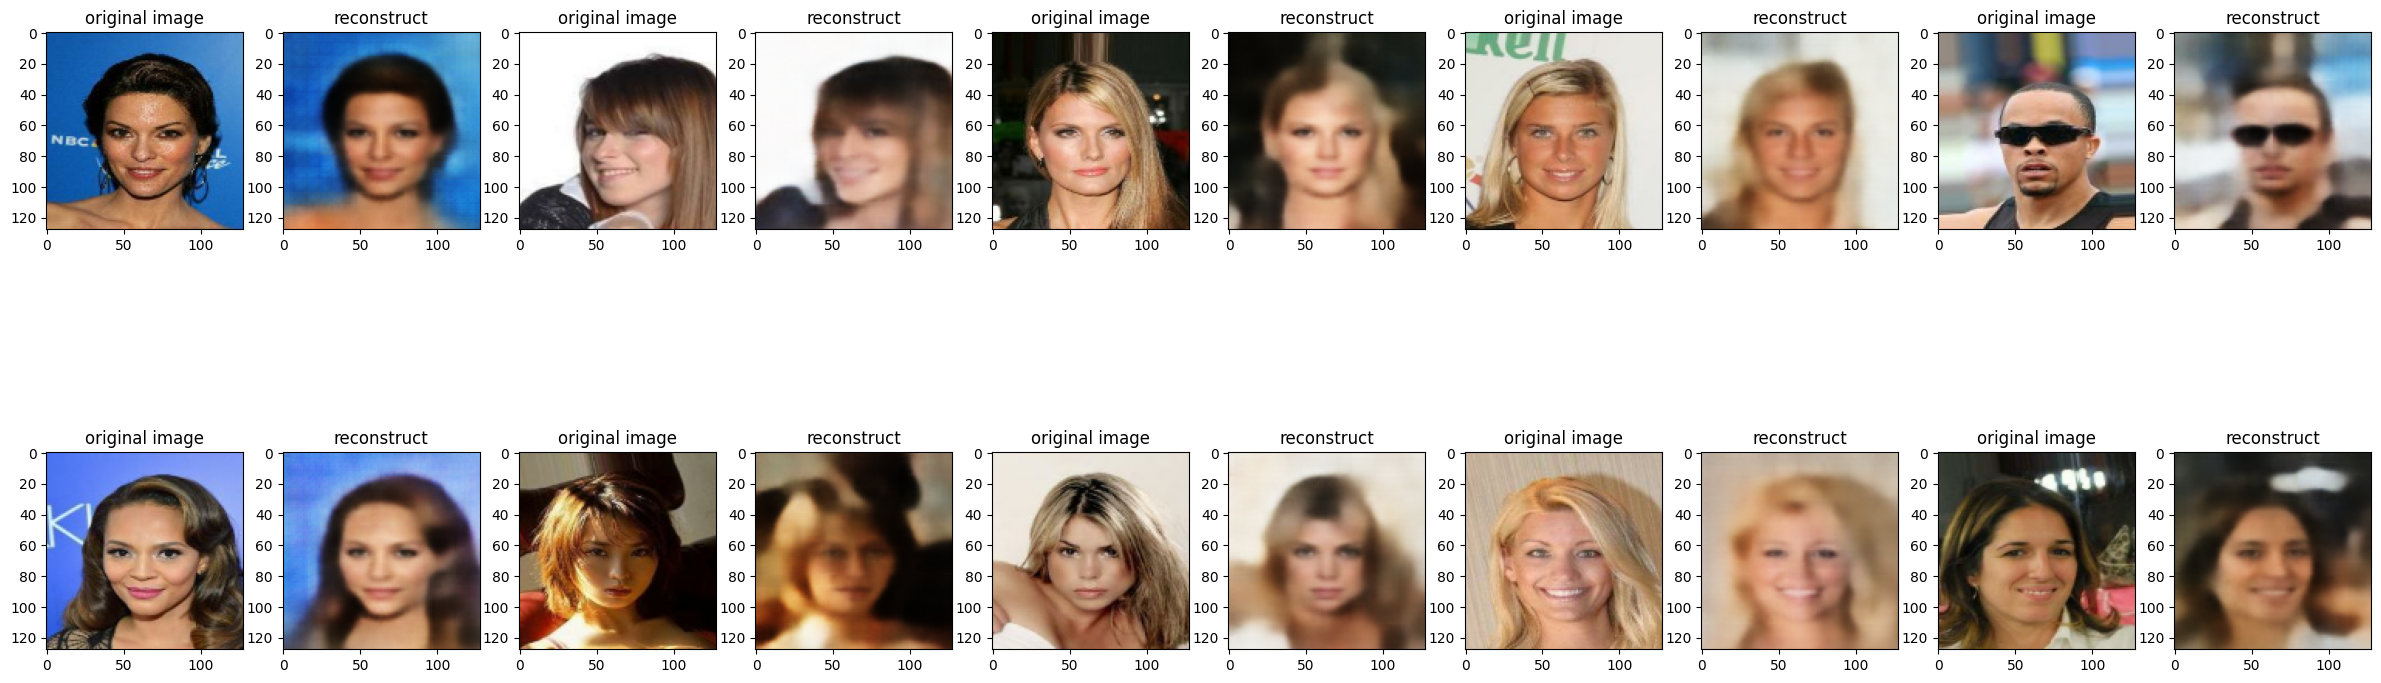

In [11]:
data = list(test_dataset.take(20))

fig = plt.figure(figsize=(30, 10))
for n in range(0, 20, 2):
    image = autoencoder.predict(data[n])
    
    plt.subplot(2, 10, n + 1)
    plt.imshow(np.squeeze(data[n]))
    plt.title('original image')
    
    plt.subplot(2, 10, n + 2)
    plt.imshow(np.squeeze(image))
    plt.title('reconstruct')
    
plt.show()

<h4>Autoencoder Decoding with noise</h4>
We can observe that the reconstructed images are becoming more distorted then noise is added to their encodings.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


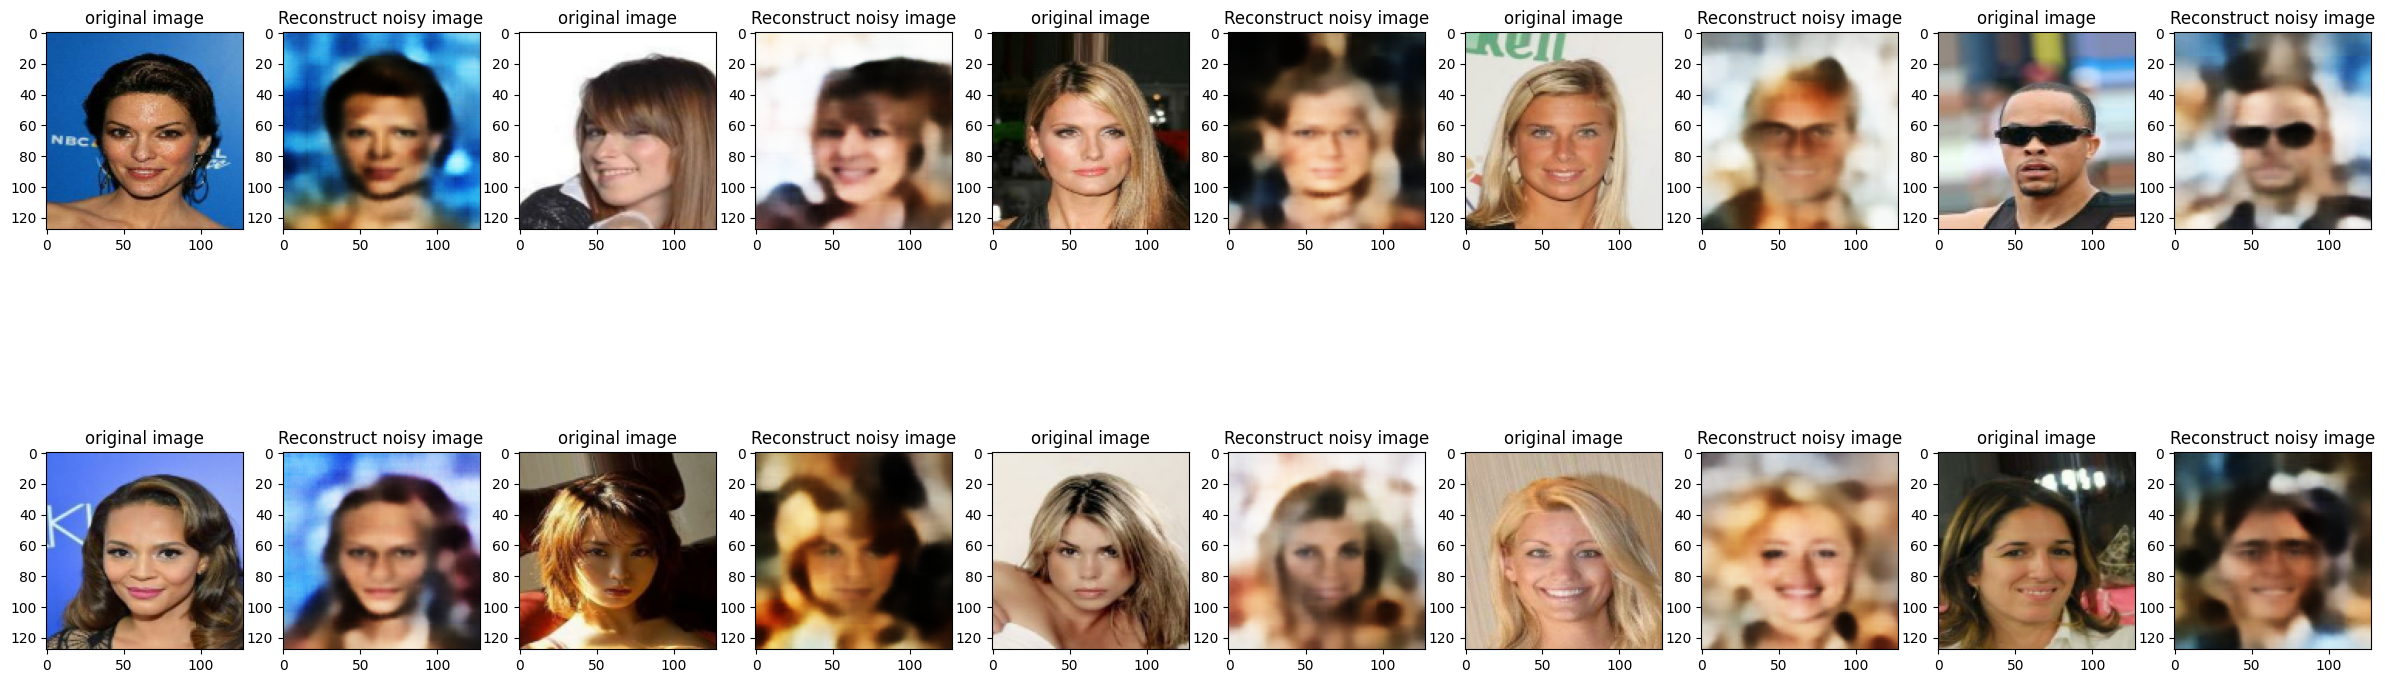

In [12]:
data = list(test_dataset.take(20))

fig = plt.figure(figsize=(30, 10))
for n in range(0, 20, 2):
    image = encoder.predict(data[n])
    image += np.random.normal(0.0, 1.0, size = (Z_DIM)) #inject noise to the encoded vector
    reconst_images = decoder.predict(image)
    
    plt.subplot(2, 10, n + 1)
    plt.imshow(np.squeeze(data[n]))
    plt.title('original image')
    
    plt.subplot(2, 10, n + 2)
    plt.imshow(np.squeeze(reconst_images))
    plt.title('Reconstruct noisy image')
    
plt.show()

<h4>Limitations of autoencoders for content generation</h4>
Once the autoencoder network has been trained, we have both an encoder and a decoder but there is no real way to produce any new content. This is because a generation of meaningful content depends on the regularity of the output latent space by the encoder for the decoder to generate the new content. Pretty much, is to get the decoder to work more or less like the generator of a Generative Adversarial Network.

In a conventional autoencoder network, this regularity of the out latent space from the encoder is almost impossible. It depends on the distribution of the data in the initial space, the dimension of the latent space and the architecture of the encoder. There's no way that the encoder will organize the latent space in a smart way compatible with the generative process to produce new content

<h4>Variable Autoencoder</h4>
A variational autoencoder can be defined as being an autoencoder whose training is regularised to avoid overfitting and ensure that the latent space has good properties that enable generative process. A variational autoencoder is an architecture composed of both an encoder and a decoder and is trained to minimise the reconstruction error between the encoded-decoded data and the initial data. In addition, regularisation of the latent space is introduced within the process of encoding-decoding. This is done via a slight modification where instead of encoding an input as a single point, we encode it as a distribution over the latent space. The model is then trained as follows:

1. The input is encoded as distribution over the latent space<br>
2. A point from the latent space is sampled from that distribution<br>
3. The sampled point is decoded and the reconstruction error can be computed<br>
4. The reconstruction error is backpropagated through the network<br>
   
The loss function used is the sum of RMSE and KL Divergence. A weight is assigned to the RMSE loss, known as the loss factor. The loss factor is multiplied with the RMSE loss. If we use a high loss factor, the drawbacks of a Simple Autoencoder start to appear. However, if we use a loss factor too low, the quality of the reconstructed images will be poor. Hence the loss factor is a hyperparameter that needs to be tuned.

The section covers the definition of the Variable Autoencoder defined within a VariableAutoencoder Class.

In [13]:
import keras
from keras import layers
import tensorflow as tf

class Sampling(layers.Layer):
    
    def call(self, inputs):
        
        z_mean, z_log_var = inputs
        
        batch = tf.shape(z_mean)[0]
        dim = tf.shape(z_mean)[1]
        
        epsilon = tf.random.normal(shape=(batch, dim))
        
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

In [14]:
def build_encoder(input_dim=(128,128,3), z_dim=200):

    encoder_inputs = keras.Input(shape=input_dim)

    # Doubled filter counts + BatchNorm for stability and capacity
    x = layers.Conv2D(32, (3,3), strides=2, padding='same')(encoder_inputs)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2D(64, (3,3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2D(128, (3,3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2D(256, (3,3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    shape_before_flatten = x.shape[1:]
    x = layers.Flatten()(x)

    z_mean    = layers.Dense(z_dim, name='z_mean')(x)
    z_log_var = layers.Dense(z_dim, name='z_log_var')(x)
    z = Sampling()([z_mean, z_log_var])

    encoder = keras.Model(encoder_inputs, [z_mean, z_log_var, z], name='encoder')
    return encoder, shape_before_flatten


In [15]:
import numpy as np

def build_decoder(shape_before_flatten, z_dim=200):

    latent_inputs = keras.Input(shape=(z_dim,))

    x = layers.Dense(int(np.prod(shape_before_flatten)), use_bias=False)(latent_inputs)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)
    x = layers.Reshape(shape_before_flatten)(x)

    x = layers.Conv2DTranspose(256, (3,3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2DTranspose(128, (3,3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2DTranspose(64, (3,3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2DTranspose(32, (3,3), strides=2, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    # Refinement conv at full resolution for sharper details
    x = layers.Conv2D(32, (3,3), strides=1, padding='same')(x)
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU()(x)

    x = layers.Conv2DTranspose(3, (3,3), strides=1, padding='same')(x)
    decoder_outputs = layers.Activation('sigmoid')(x)

    decoder = keras.Model(latent_inputs, decoder_outputs, name='decoder')
    return decoder


In [16]:
class VAE(keras.Model):

    def __init__(self, encoder, decoder, beta=0.5, use_perceptual=True, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        # beta < 1 reduces KL regularisation -> sharper reconstructions
        self.beta = beta
        self.use_perceptual = use_perceptual

        if use_perceptual:
            # Frozen VGG16 for perceptual (feature-matching) loss
            vgg = keras.applications.VGG16(
                include_top=False, weights='imagenet', input_shape=(128, 128, 3)
            )
            vgg.trainable = False
            self.perceptual_model = keras.Model(
                inputs=vgg.input,
                outputs=[
                    vgg.get_layer('block2_conv2').output,  # low-level textures
                    vgg.get_layer('block3_conv3').output,  # mid-level structure
                ],
                name='perceptual',
            )

        self.total_loss_tracker          = keras.metrics.Mean(name='total_loss')
        self.reconstruction_loss_tracker = keras.metrics.Mean(name='reconstruction_loss')
        self.kl_loss_tracker             = keras.metrics.Mean(name='kl_loss')

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def call(self, inputs):
        z_mean, z_log_var, z = self.encoder(inputs)
        return self.decoder(z)

    def compute_loss(self, x, z_mean, z_log_var, reconstruction):
        # -- SSIM loss: preserves edges, luminance, contrast -----------------
        ssim_val  = tf.reduce_mean(tf.image.ssim(x, reconstruction, max_val=1.0))
        ssim_loss = (1.0 - ssim_val) * (128 * 128)   # scaled to pixel-sum space

        # -- BCE loss: pixel-level accuracy ----------------------------------
        bce_loss = tf.reduce_mean(
            keras.losses.binary_crossentropy(x, reconstruction)
        ) * (128 * 128)

        reconstruction_loss = 0.5 * ssim_loss + 0.5 * bce_loss

        # -- Perceptual loss: VGG feature matching ---------------------------
        if self.use_perceptual:
            # Scale [0,1] -> [0,255] then apply ImageNet mean subtraction
            x_vgg   = keras.applications.vgg16.preprocess_input(x * 255.0)
            rec_vgg = keras.applications.vgg16.preprocess_input(reconstruction * 255.0)
            real_feats = self.perceptual_model(x_vgg,   training=False)
            fake_feats = self.perceptual_model(rec_vgg, training=False)
            perc_loss = tf.add_n([
                tf.reduce_mean(tf.abs(rf - ff))
                for rf, ff in zip(real_feats, fake_feats)
            ])
            # Tune perc_weight (0.05-0.5) if images look too noisy or too smooth
            reconstruction_loss = reconstruction_loss + 0.1 * perc_loss

        # -- KL divergence ---------------------------------------------------
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1
            )
        )

        total_loss = reconstruction_loss + self.beta * kl_loss
        return total_loss, reconstruction_loss, kl_loss

    def train_step(self, data):
        if isinstance(data, tuple):
            x, _ = data
        else:
            x = data

        with tf.GradientTape() as tape:
            z_mean, z_log_var, z = self.encoder(x, training=True)
            reconstruction = self.decoder(z, training=True)
            total_loss, reconstruction_loss, kl_loss = self.compute_loss(
                x, z_mean, z_log_var, reconstruction
            )

        grads = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            'loss': self.total_loss_tracker.result(),
            'reconstruction_loss': self.reconstruction_loss_tracker.result(),
            'kl_loss': self.kl_loss_tracker.result(),
        }

    def test_step(self, data):
        if isinstance(data, tuple):
            x, _ = data
        else:
            x = data

        z_mean, z_log_var, z = self.encoder(x, training=False)
        reconstruction = self.decoder(z, training=False)
        total_loss, reconstruction_loss, kl_loss = self.compute_loss(
            x, z_mean, z_log_var, reconstruction
        )

        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)

        return {
            'loss': self.total_loss_tracker.result(),
            'reconstruction_loss': self.reconstruction_loss_tracker.result(),
            'kl_loss': self.kl_loss_tracker.result(),
        }


In [17]:
input_dim = (128, 128, 3)
z_dim = 200

encoder, shape_before_flatten = build_encoder(input_dim, z_dim)
decoder = build_decoder(shape_before_flatten, z_dim)

# beta=0.5       -> halves the KL penalty, letting the decoder focus on detail
# use_perceptual -> VGG feature matching for realistic textures
# NOTE: batch_size=16 recommended for CPU; increase to 32-64 on GPU
vae = VAE(encoder, decoder, beta=0.5, use_perceptual=False)  # set True when GPU is available

dummy = tf.zeros((1, 128, 128, 3))
vae(dummy)

vae.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005)
)


In [18]:
encoder.summary()
decoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_7       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     18,496 │ leaky_re_lu_7[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_8       │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │     73,856 │ leaky_re_lu_8[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_9       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 8, 8, 256) │    295,168 │ leaky_re_lu_9[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 256) │      1,024 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_10      │ (None, 8, 8, 256) │          0 │ batch_normalizat… │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 16384)     │          0 │ leaky_re_lu_10[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 200)       │  3,277,000 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 200)       │  3,277,000 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 200)       │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,944,336 (26.49 MB)

 Trainable params: 6,943,376 (26.49 MB)

 Non-trainable params: 960 (3.75 KB)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16384)          │     3,276,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16384)          │        65,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 16, 16, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 32, 32, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_13 (LeakyReLU)      │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_6              │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_14 (LeakyReLU)      │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_7              │ (None, 128, 128, 32)   │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_15 (LeakyReLU)      │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_16 (LeakyReLU)      │ (None, 128, 128, 32)   │             

 Total params: 4,331,875 (16.52 MB)

 Trainable params: 4,298,083 (16.40 MB)

 Non-trainable params: 33,792 (132.00 KB)

In [19]:
vae.summary()

Model: "vae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Functional)            │ ((None, 200), (None,   │     6,944,336 │
│                                 │ 200), (None, 200))     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 128, 128, 3)    │     4,331,875 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,276,211 (43.02 MB)

 Trainable params: 11,241,459 (42.88 MB)

 Non-trainable params: 34,752 (135.75 KB)

In [20]:
VAE_N_EPOCHS = 10

checkpoint_vae_best = ModelCheckpoint(os.path.join(WEIGHTS_FOLDER, 'VAE/vae_best.weights.h5'), 
                                      monitor='val_loss',
                                      mode='min',
                                      save_best_only=True,
                                      save_weights_only = True, 
                                      verbose=1)
    
checkpoint_vae_last = ModelCheckpoint(os.path.join(WEIGHTS_FOLDER, 'VAE/vae_epoch_{epoch:02d}.weights.h5'),
                                      monitor='val_loss',
                                      mode='min',
                                      verbose=1,
                                      save_best_only=False,
                                      save_weights_only=True)

vae.fit(train_dataset,
        epochs=VAE_N_EPOCHS,
        callbacks=[checkpoint_vae_best,checkpoint_vae_last],
        validation_data=valid_dataset)

Epoch 1/10
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 0s 308ms/step - kl_loss: 409.5590 - loss: 8056.7193 - reconstruction_loss: 7851.9384
Epoch 1: val_loss improved from None to 6990.04346, saving model to generate_faces/weights/VAE/vae_best.weights.h5

Epoch 1: finished saving model to generate_faces/weights/VAE/vae_best.weights.h5

Epoch 1: saving model to generate_faces/weights/VAE/vae_epoch_01.weights.h5

Epoch 1: finished saving model to generate_faces/weights/VAE/vae_epoch_01.weights.h5
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 3395s 335ms/step - kl_loss: 411.6390 - loss: 7506.0991 - reconstruction_loss: 7300.2764 - val_kl_loss: 407.7591 - val_loss: 6990.0435 - val_reconstruction_loss: 6786.1714
Epoch 2/10
10130/10130 ━━━━━━━━━━━━━━━━━━━━ 0s 325ms/step - kl_loss: 410.6265 - loss: 7101.2438 - reconstruction_loss: 6895.9294
Epoch 2: val_loss improved from 6990.04346 to 6876.20752, saving model to generate_faces/weights/VAE/vae_best.weights.h5

Epoch 2: finished saving model to generate_faces/weights

In [23]:
test_dataset = build_dataset(valid_paths, test=True)

In [24]:
vae.load_weights('generate_faces/weights/VAE/vae_best.weights.h5')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 439ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


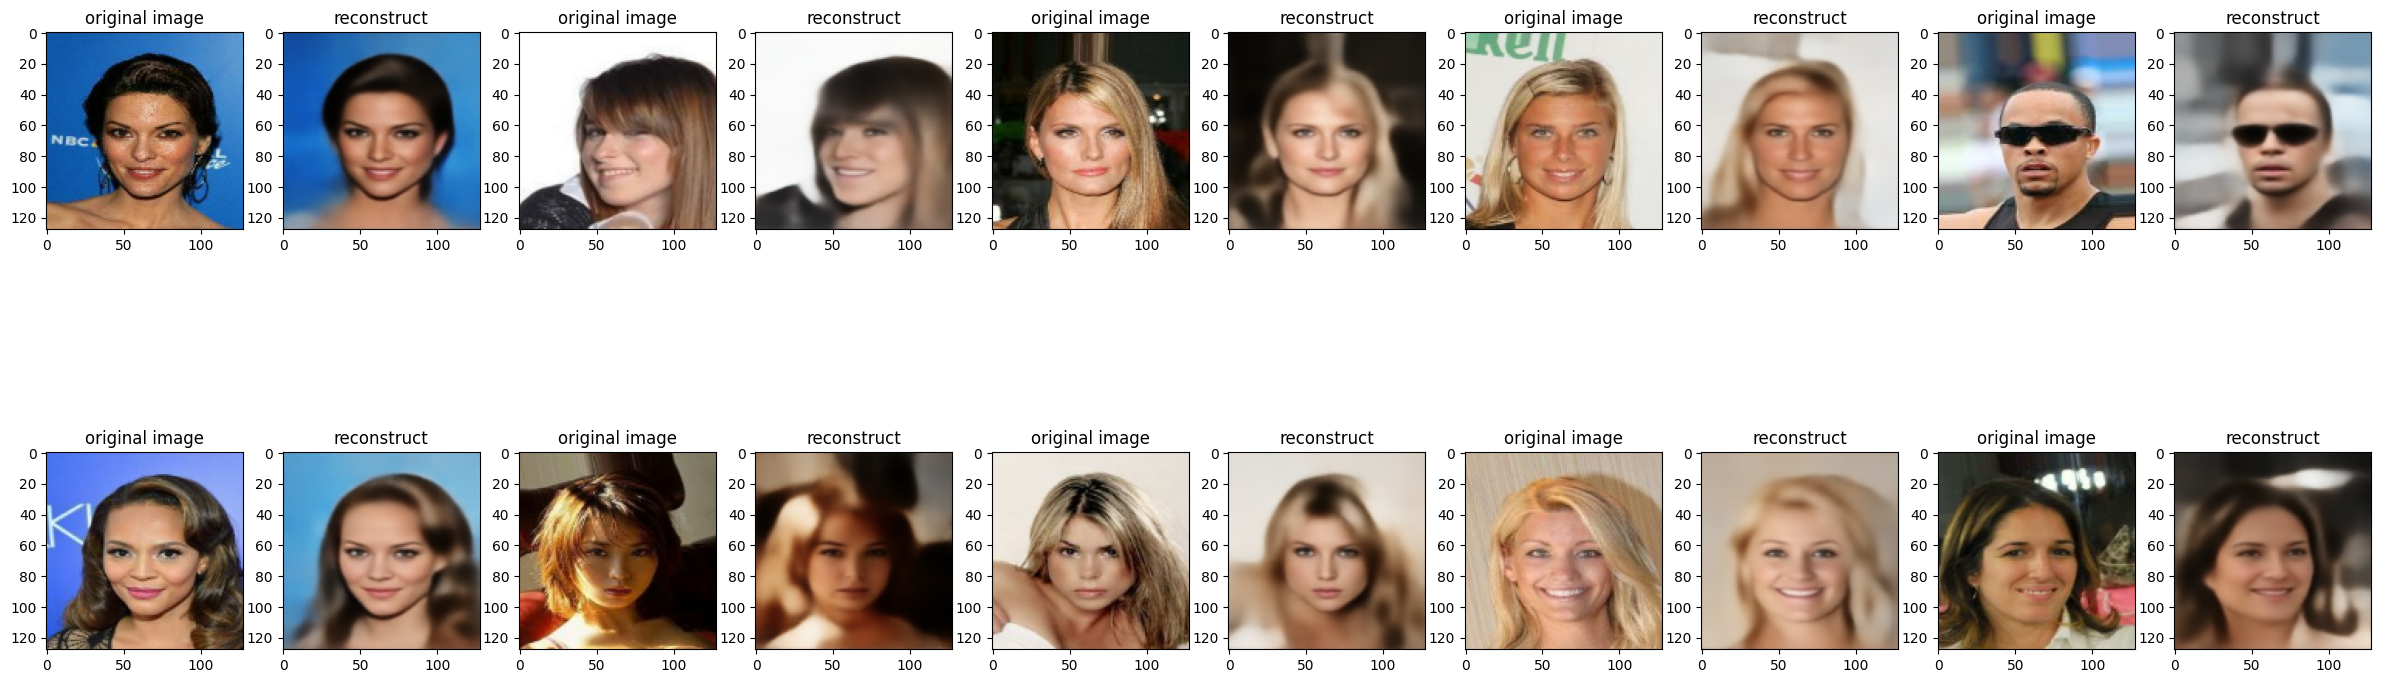

In [25]:
data = list(test_dataset.take(20))

fig = plt.figure(figsize=(30, 10))
for n in range(0, 20, 2):
    image = vae.predict(data[n])
    
    plt.subplot(2, 10, n + 1)
    plt.imshow(np.squeeze(data[n]))
    plt.title('original image')
    
    plt.subplot(2, 10, n + 2)
    plt.imshow(np.squeeze(image))
    plt.title('reconstruct')
    
plt.show()

<h4>Generate new faces using the Variable Autoencoder</h4>
The Variable Autoencoder is capable enough of producing new faces from vectors samped from a standard normal distribution - although the output of the generated faces are not as good quality.

In [26]:
def vae_generate_images(new_to_show=10):
    random_codes = np.random.normal(size=(new_to_show, 200))
    new_faces = decoder.predict(np.array(random_codes))

    fig = plt.figure(figsize=(30, 15))

    for i in range(new_to_show):
        ax = fig.add_subplot(6, 10, i+1)
        ax.imshow(new_faces[i])
        ax.axis('off')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step


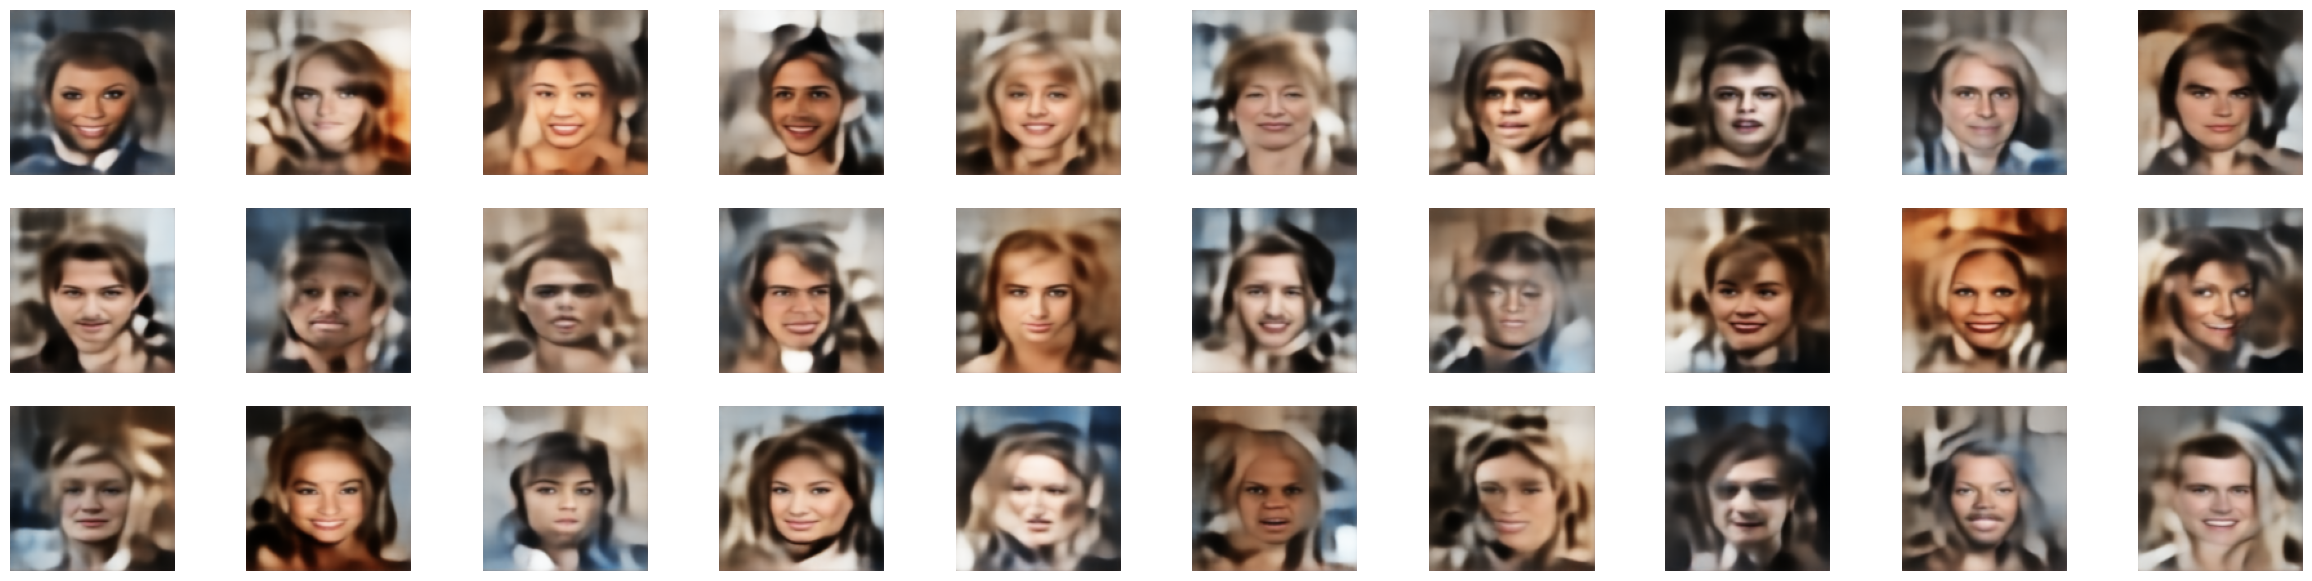

In [27]:
vae_generate_images(30)